# Object detection — inference test (CPU-friendly)

Runs the five detectors we discussed on the same 10 images and shows/saves every output.

| # | Model | Type | Classes | Runs on CPU? |
|---|---|---|---|---|
| 1 | **YOLOX-S** | CNN, anchor-free YOLO | 80 COCO (fixed) | ✅ yes — fast |
| 2 | **YOLOX-X** | CNN, anchor-free YOLO | 80 COCO (fixed) | ✅ yes — slower (≈10× the compute of S) |
| 3 | **RT-DETR R50-VD** | DETR transformer, no NMS | 80 COCO (fixed) | ✅ yes |
| 4 | **OWLv2 base/16 ensemble** | CLIP-based, open-vocabulary | any text you type | ✅ yes — slowest (960×960 input) |
| 5 | **Grounding DINO tiny** | DETR + BERT, open-vocabulary | any text you type | ✅ yes — slow |

**None of these need a GPU.** A GPU only makes them faster; the notebook picks `cuda` automatically if one exists.
Measured CPU timings are in the summary at the end.

**Images** (`images/`): 8 everyday photos from the COCO val2017 set (Flickr, various Creative Commons licenses) +
1 synthetic invoice (katanaml invoices dataset) + 1 receipt photo (CORD dataset). The two documents are there on
purpose: COCO-trained detectors have no "document" classes, open-vocabulary ones can be asked for "a table", "a logo"…

**Outputs** (`outputs/`): annotated images per model, `detections.csv` (every box), `summary.csv` (counts + timings).

Kernel: **Python (detect)** — see `README.md` for the environment setup.

In [1]:
import gc, os, time, urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from PIL import Image, ImageDraw, ImageFont

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(os.cpu_count())
print(f"device: {DEVICE} | torch {torch.__version__} | CPU threads: {torch.get_num_threads()}")

ROOT = Path.cwd()
IMG_DIR, OUT_DIR, W_DIR = ROOT / "images", ROOT / "outputs", ROOT / "weights"
OUT_DIR.mkdir(exist_ok=True); W_DIR.mkdir(exist_ok=True)

IMAGE_PATHS = sorted(IMG_DIR.glob("*.jpg"))
IMAGES = {p.stem: Image.open(p).convert("RGB") for p in IMAGE_PATHS}
DOC_IMAGES = {"09_invoice", "10_receipt"}
print(len(IMAGES), "images:", ", ".join(IMAGES))

device: cpu | torch 2.15.0+cpu | CPU threads: 8
10 images: 01_cats_remotes, 02_living_room, 03_group_of_kids, 04_street_cars, 05_sidewalk_people, 06_kitchen, 07_stop_sign, 08_dog_clutter, 09_invoice, 10_receipt


## Settings

- **Thresholds** — boxes below these scores are dropped. Open-vocabulary models produce much lower scores than COCO detectors, so their thresholds are lower.
- **Text prompts** — only used by OWLv2 and Grounding DINO. Photos get an everyday-object list; the two documents get a document-element list. Edit freely.

In [2]:
COCO_THRESHOLD  = 0.50   # YOLOX, RT-DETR
OWL_THRESHOLD   = 0.20   # OWLv2 scores are low by design (0.1–0.3 is normal)
GDINO_BOX_THR   = 0.35   # Grounding DINO: "is there a matching object here?"
GDINO_TEXT_THR  = 0.25   # Grounding DINO: "which words does this box match?"

PHOTO_PROMPTS = ["a person", "a cat", "a dog", "a car", "a bicycle", "a remote control",
                 "a stop sign", "a cup", "a bottle", "a chair", "a television", "a backpack"]
DOC_PROMPTS   = ["a table", "a logo", "a signature", "a stamp", "a barcode"]

def prompts_for(name):
    return DOC_PROMPTS if name in DOC_IMAGES else PHOTO_PROMPTS

## Helpers — drawing, display, result collection

In [3]:
ALL_ROWS, SUMMARY = [], []
_PALETTE = plt.get_cmap("tab20").colors

def _color(label):
    r, g, b = _PALETTE[hash(label) % len(_PALETTE)]
    return int(r * 255), int(g * 255), int(b * 255)

def draw(img, dets):
    # dets: list of dicts with label, score, box=[x1,y1,x2,y2] in original-image pixels
    im = img.copy(); d = ImageDraw.Draw(im)
    lw = max(2, round(max(im.size) / 300))
    try:
        font = ImageFont.truetype("DejaVuSans.ttf", max(12, round(max(im.size) / 45)))
    except OSError:
        font = ImageFont.load_default()
    for det in dets:
        x1, y1, x2, y2 = det["box"]; c = _color(det["label"])
        d.rectangle([x1, y1, x2, y2], outline=c, width=lw)
        txt = f'{det["label"]} {det["score"]:.2f}'
        tb = d.textbbox((x1, y1), txt, font=font)
        d.rectangle([tb[0], tb[1] - 2, tb[2] + 4, tb[3] + 2], fill=c)
        d.text((x1 + 2, y1), txt, fill="white", font=font)
    return im

def record(model_name, results, load_s, times):
    # Save annotated images + rows, show a grid and a table
    out = OUT_DIR / model_name; out.mkdir(exist_ok=True)
    fig, axes = plt.subplots(2, 5, figsize=(25, 10))
    for ax, (name, dets) in zip(axes.flat, results.items()):
        vis = draw(IMAGES[name], dets); vis.save(out / f"{name}.jpg")
        ax.imshow(vis); ax.set_title(f"{name}\n{len(dets)} detections, {times[name]:.2f}s", fontsize=11); ax.axis("off")
        for det in dets:
            ALL_ROWS.append({"model": model_name, "image": name, "label": det["label"],
                             "score": round(float(det["score"]), 3),
                             **dict(zip(["x1", "y1", "x2", "y2"], [round(float(v), 1) for v in det["box"]]))})
    fig.suptitle(model_name, fontsize=16); plt.tight_layout(); plt.show()

    n = sum(len(v) for v in results.values()); per_img = np.mean(list(times.values()))
    SUMMARY.append({"model": model_name, "device": DEVICE, "load_s": round(load_s, 1),
                    "avg_s_per_image": round(per_img, 2), "total_detections": n})
    print(f"{model_name}: load {load_s:.1f}s | avg {per_img:.2f}s/image | {n} detections total")
    df = pd.DataFrame([r for r in ALL_ROWS if r["model"] == model_name])
    if not df.empty:
        display(df.groupby("image")["label"].agg(lambda s: ", ".join(f"{k}×{v}" for k, v in s.value_counts().items()))
                  .rename("detections").to_frame())

def free(*objs):
    for o in objs:
        del o
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

---
## 1 & 2. YOLOX-S and YOLOX-X

> **What it does:** a fast, anchor-free YOLO-family detector (Megvii, 2021). In one pass it finds every object
> from a **fixed list of 80 COCO classes** (person, car, cat, cup, …) and draws a box around each.
> **S** (9M params) is the small, fast version; **X** (99M params) is the large, more accurate one.
>
> | | |
> |---|---|
> | **Input** | one RGB image (any size; resized + padded to 640×640 internally) |
> | **Output** | a list of detections, each = **box** `[x1, y1, x2, y2]` in pixels + **class** (one of 80 COCO names) + **score** (0–1) |
> | **Needs from you** | nothing but the image — the class list is fixed |
>
> Example output from this run (`01_cats_remotes`, YOLOX-S):
> `cat  0.93  [5, 55, 318, 471]` · `cat  0.92  [341, 25, 636, 373]`

**Implementation notes:** uses Megvii's official `.onnx` files with ONNX Runtime, so the YOLOX repo doesn't need to be
built. Pre/post-processing follows the repo's `demo/ONNXRuntime/onnx_inference.py`: letterbox to 640×640 (gray padding,
BGR, no normalization) → decode the grid outputs → score = objectness × class prob → class-aware **NMS** (YOLO-style
detectors produce duplicate boxes and need it). Downloads: YOLOX-S ≈ 36 MB, YOLOX-X ≈ 396 MB (once, into `weights/`).

In [4]:
import onnxruntime as ort

COCO_CLASSES = ["person","bicycle","car","motorcycle","airplane","bus","train","truck","boat","traffic light",
    "fire hydrant","stop sign","parking meter","bench","bird","cat","dog","horse","sheep","cow","elephant","bear",
    "zebra","giraffe","backpack","umbrella","handbag","tie","suitcase","frisbee","skis","snowboard","sports ball",
    "kite","baseball bat","baseball glove","skateboard","surfboard","tennis racket","bottle","wine glass","cup",
    "fork","knife","spoon","bowl","banana","apple","sandwich","orange","broccoli","carrot","hot dog","pizza","donut",
    "cake","chair","couch","potted plant","bed","dining table","toilet","tv","laptop","mouse","remote","keyboard",
    "cell phone","microwave","oven","toaster","sink","refrigerator","book","clock","vase","scissors","teddy bear",
    "hair drier","toothbrush"]
YOLOX_URL = "https://github.com/Megvii-BaseDetection/YOLOX/releases/download/0.1.1rc0/{}.onnx"

def yolox_preprocess(img_rgb, size=640):
    bgr = cv2.cvtColor(np.asarray(img_rgb), cv2.COLOR_RGB2BGR)
    h, w = bgr.shape[:2]; r = min(size / h, size / w)
    padded = np.full((size, size, 3), 114, dtype=np.uint8)
    padded[: int(h * r), : int(w * r)] = cv2.resize(bgr, (int(w * r), int(h * r)), interpolation=cv2.INTER_LINEAR)
    return np.ascontiguousarray(padded.transpose(2, 0, 1)[None], dtype=np.float32), r

def yolox_postprocess(out, ratio, size=640, conf=COCO_THRESHOLD, iou=0.45):
    grids, strides = [], []
    for s in (8, 16, 32):
        g = size // s; xv, yv = np.meshgrid(np.arange(g), np.arange(g))
        grids.append(np.stack((xv, yv), 2).reshape(1, -1, 2)); strides.append(np.full((1, g * g, 1), s))
    grids, strides = np.concatenate(grids, 1), np.concatenate(strides, 1)
    out[..., :2] = (out[..., :2] + grids) * strides          # box centers
    out[..., 2:4] = np.exp(out[..., 2:4]) * strides          # box width/height
    p = out[0]
    scores_all = p[:, 4:5] * p[:, 5:]                        # objectness × class prob
    cls = scores_all.argmax(1); scores = scores_all.max(1)
    keep = scores >= conf
    if not keep.any():
        return []
    b = p[keep, :4]; boxes = np.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2,
                                       b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], 1) / ratio
    bt, st, ct = torch.from_numpy(boxes).float(), torch.from_numpy(scores[keep]).float(), torch.from_numpy(cls[keep])
    idx = torchvision.ops.batched_nms(bt, st, ct, iou).numpy()
    return [{"label": COCO_CLASSES[int(ct[i])], "score": float(st[i]), "box": boxes[i].tolist()} for i in idx]

def run_yolox(variant):
    path = W_DIR / f"{variant}.onnx"
    if not path.exists():
        # download to a .part file and rename only when complete, so an interrupted
        # download is never mistaken for a finished one
        print(f"downloading {path.name} ...")
        tmp = path.with_suffix(".onnx.part")
        urllib.request.urlretrieve(YOLOX_URL.format(variant), tmp)
        tmp.rename(path)
    providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if DEVICE == "cuda" else ["CPUExecutionProvider"]
    t = time.time(); sess = ort.InferenceSession(str(path), providers=providers); load_s = time.time() - t
    inp = sess.get_inputs()[0].name
    results, times = {}, {}
    for name, img in IMAGES.items():
        t = time.time()
        x, r = yolox_preprocess(img)
        results[name] = yolox_postprocess(sess.run(None, {inp: x})[0], r)
        times[name] = time.time() - t
    record("YOLOX-" + variant.split("_")[1].upper(), results, load_s, times)
    free(sess)

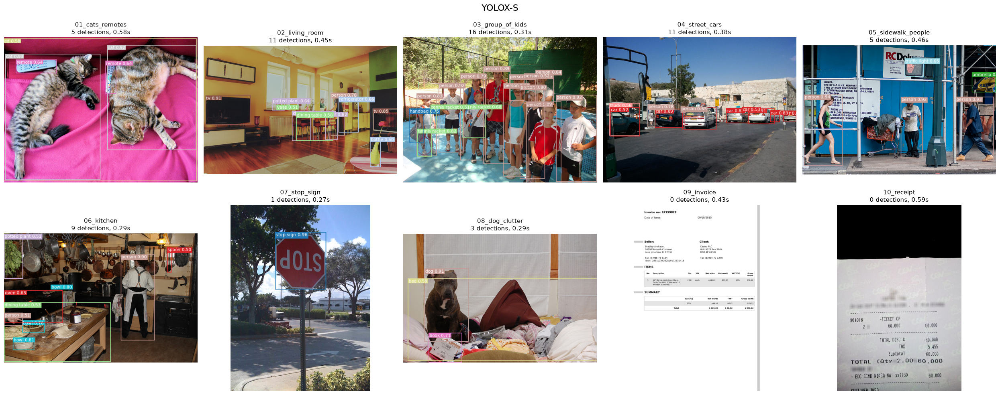

YOLOX-S: load 0.4s | avg 0.41s/image | 61 detections total


,detections
image,
01_cats_remotes,"cat×2, remote×2, bed×1"
02_living_room,"chair×3, tv×2, person×1, refrigerator×1, potte..."
03_group_of_kids,"person×12, tennis racket×3, handbag×1"
04_street_cars,"car×8, person×2, truck×1"
05_sidewalk_people,"person×3, traffic light×1, umbrella×1"
06_kitchen,"bowl×3, person×2, oven×1, dining table×1, pott..."
07_stop_sign,stop sign×1
08_dog_clutter,"dog×1, book×1, bed×1"


In [5]:
run_yolox("yolox_s")

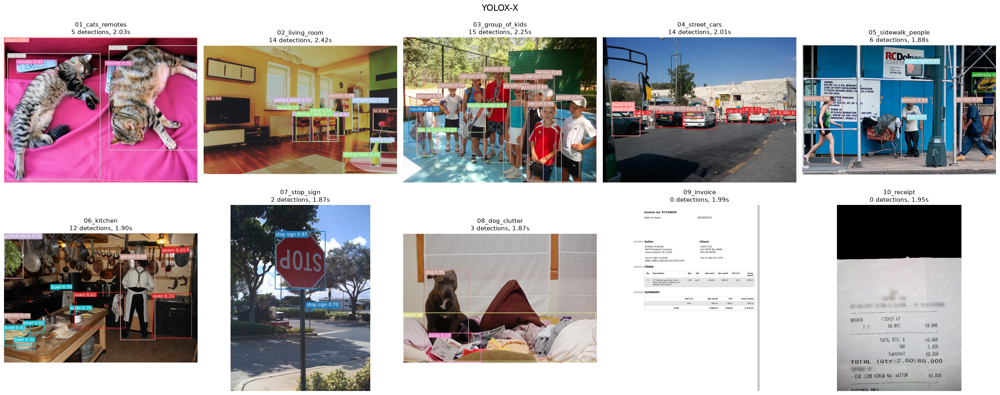

YOLOX-X: load 1.8s | avg 2.02s/image | 71 detections total


,detections
image,
01_cats_remotes,"cat×2, remote×2, couch×1"
02_living_room,"chair×3, vase×3, tv×2, dining table×2, person×..."
03_group_of_kids,"person×12, tennis racket×2, handbag×1"
04_street_cars,"car×9, person×3, truck×2"
05_sidewalk_people,"person×3, traffic light×1, umbrella×1, cup×1"
06_kitchen,"bowl×4, person×2, spoon×2, oven×2, knife×1, po..."
07_stop_sign,stop sign×2
08_dog_clutter,"dog×1, bed×1, book×1"


In [6]:
run_yolox("yolox_x")

---
## 3. RT-DETR R50-VD (`PekingU/rtdetr_r50vd`)

> **What it does:** a real-time **transformer** detector (Baidu, 2024) — a DETR that is fast enough to compete with
> YOLOs. Same job and same **80 COCO classes** as YOLOX, but it predicts a fixed set of 300 "object queries" that each
> claim one object, so there are **no duplicate boxes and no NMS step**. Backbone: ResNet-50-vd (42M params).
>
> | | |
> |---|---|
> | **Input** | one RGB image (resized to 640×640 internally) |
> | **Output** | a list of detections, each = **box** `[x1, y1, x2, y2]` in pixels + **class** (80 COCO names) + **score** (0–1) |
> | **Needs from you** | nothing but the image |
>
> Example output from this run (`01_cats_remotes`):
> `sofa  0.97  [0, 0, 640, 476]` · `cat  0.96  [343, 24, 640, 372]`

**Note:** this checkpoint's label names use the older style (`sofa`, `tvmonitor`, `pottedplant`) where YOLOX says
`couch`, `tv`, `potted plant` — same classes, different spelling.

Loading weights:   0%|          | 0/764 [00:00<?, ?it/s]

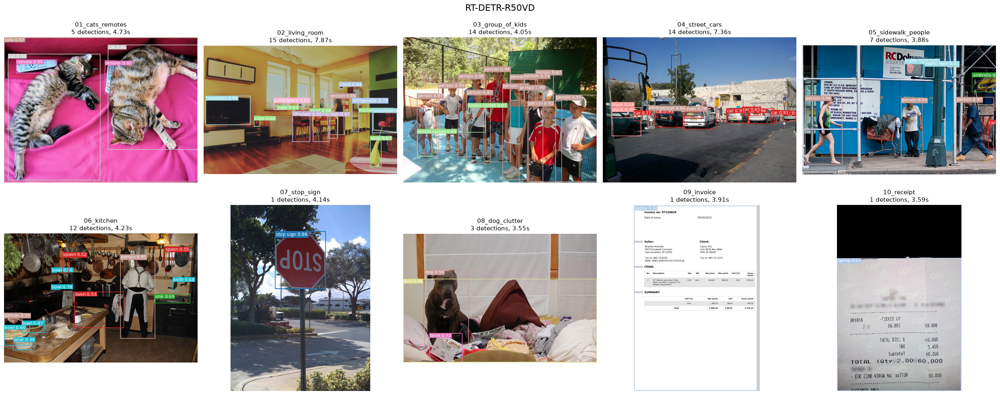

RT-DETR-R50VD: load 2.0s | avg 4.73s/image | 73 detections total


,detections
image,
01_cats_remotes,"cat×2, remote×2, sofa×1"
02_living_room,"chair×4, vase×4, tvmonitor×2, person×1, clock×..."
03_group_of_kids,"person×12, tennis racket×2"
04_street_cars,"car×9, person×3, truck×2"
05_sidewalk_people,"person×3, traffic light×2, umbrella×1, car×1"
06_kitchen,"bowl×5, person×2, spoon×2, sink×1, knife×1, ov..."
07_stop_sign,stop sign×1
08_dog_clutter,"dog×1, book×1, bed×1"
09_invoice,laptop×1


In [7]:
from transformers import RTDetrForObjectDetection, RTDetrImageProcessor

t = time.time()
proc = RTDetrImageProcessor.from_pretrained("PekingU/rtdetr_r50vd")
model = RTDetrForObjectDetection.from_pretrained("PekingU/rtdetr_r50vd").to(DEVICE).eval()
load_s = time.time() - t

results, times = {}, {}
for name, img in IMAGES.items():
    t = time.time()
    inputs = proc(images=img, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = model(**inputs)
    res = proc.post_process_object_detection(out, target_sizes=torch.tensor([img.size[::-1]]), threshold=COCO_THRESHOLD)[0]
    results[name] = [{"label": model.config.id2label[int(l)], "score": float(s), "box": b.tolist()}
                     for s, l, b in zip(res["scores"], res["labels"], res["boxes"])]
    times[name] = time.time() - t

record("RT-DETR-R50VD", results, load_s, times)
free(model, proc)

---
## 4. OWLv2 base/16 ensemble (`google/owlv2-base-patch16-ensemble`)

> **What it does:** an **open-vocabulary** detector (Google, 2023) built on CLIP. Instead of a fixed class list, you
> **type what to look for** ("a cat", "a signature") and it boxes anything matching. Every 16×16 patch of the image
> proposes a box, and each box is compared with your text — the best matches are kept.
>
> | | |
> |---|---|
> | **Input** | one RGB image (padded to a square, resized to 960×960 internally) **+ a list of text queries** |
> | **Output** | a list of detections, each = **box** `[x1, y1, x2, y2]` in pixels + **which query it matched** + **score** (0–1) |
> | **Needs from you** | the text queries (here: `PHOTO_PROMPTS` / `DOC_PROMPTS` from the Settings cell) |
>
> Example output from this run (`01_cats_remotes`):
> `a remote control  0.79  [41, 73, 175, 117]` · `a remote control  0.71  [335, 77, 369, 187]`
>
> ⚠️ Scores are low by design (0.1–0.3 is a normal threshold) and **very wording-sensitive**: in this run
> "a person" scored only 0.14 on the kids photo, while "a boy" scored 0.41.

**Implementation notes:**
- the processor **pads every image to a square** (bottom/right), so boxes are rescaled with the *padded* size;
- OWLv2 can return overlapping duplicates, so a light class-aware NMS (IoU 0.5) is applied for readability.

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

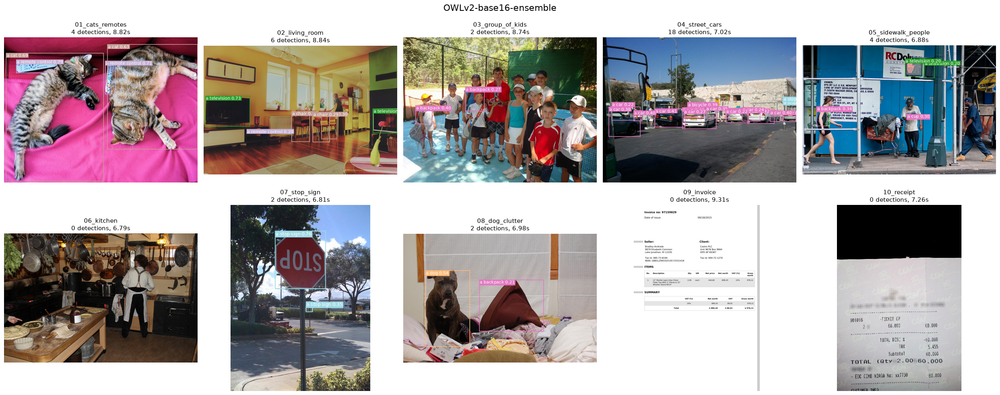

OWLv2-base16-ensemble: load 2.5s | avg 7.75s/image | 38 detections total


,detections
image,
01_cats_remotes,"a remote control×2, a cat×2"
02_living_room,"a chair×3, a television×2, a remote control×1"
03_group_of_kids,a backpack×2
04_street_cars,"a car×14, a stop sign×3, a bicycle×1"
05_sidewalk_people,"a television×2, a backpack×1, a cup×1"
07_stop_sign,a stop sign×2
08_dog_clutter,"a dog×1, a backpack×1"


In [8]:
from transformers import Owlv2ForObjectDetection, Owlv2Processor

t = time.time()
proc = Owlv2Processor.from_pretrained("google/owlv2-base-patch16-ensemble")
model = Owlv2ForObjectDetection.from_pretrained("google/owlv2-base-patch16-ensemble").to(DEVICE).eval()
load_s = time.time() - t

results, times = {}, {}
for name, img in IMAGES.items():
    queries = prompts_for(name)
    t = time.time()
    inputs = proc(text=[queries], images=img, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = model(**inputs)
    side = max(img.size)  # padded square size
    res = proc.post_process_grounded_object_detection(out, threshold=OWL_THRESHOLD,
                                                      target_sizes=torch.tensor([[side, side]]))[0]
    boxes, scores, labels = res["boxes"].cpu(), res["scores"].cpu(), res["labels"].cpu()
    keep = torchvision.ops.batched_nms(boxes, scores, labels, 0.5)
    w, h = img.size
    results[name] = [{"label": queries[int(labels[i])], "score": float(scores[i]),
                      "box": [max(0, boxes[i, 0].item()), max(0, boxes[i, 1].item()),
                              min(w, boxes[i, 2].item()), min(h, boxes[i, 3].item())]} for i in keep]
    times[name] = time.time() - t

record("OWLv2-base16-ensemble", results, load_s, times)
free(model, proc)

---
## 5. Grounding DINO tiny (`IDEA-Research/grounding-dino-tiny`)

> **What it does:** an **open-vocabulary** detector (IDEA Research, 2023) like OWLv2, but it mixes the text into the
> image analysis from the start ("early fusion"), which makes it better at descriptive phrases
> ("a man holding an umbrella"). Under the hood it is a DETR-style detector (like RT-DETR) + a BERT text encoder.
>
> | | |
> |---|---|
> | **Input** | one RGB image **+ one text prompt** listing what to find, lowercase, each item ending with a period: `"a cat. a remote control."` |
> | **Output** | a list of detections, each = **box** `[x1, y1, x2, y2]` in pixels + **the matched words from your prompt** + **score** (0–1) |
> | **Needs from you** | the prompt (built here from `PHOTO_PROMPTS` / `DOC_PROMPTS`) and two thresholds (box + text) |
>
> Example output from this run (`01_cats_remotes`):
> `a remote control  0.44  [39, 69, 177, 118]` · `a remote control  0.43  [332, 74, 371, 187]`
>
> ⚠️ With many classes in one prompt it misses objects and can merge labels (this run produced `"a cat a dog"`);
> keep prompts to a few classes for best results.

**Thresholds:** box threshold = "is something here that matches the text?", text threshold = "which words does it match?".

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

/home/tsubame/miniconda3/envs/detect/lib/python3.12/site-packages/transformers/models/grounding_dino/processing_grounding_dino.py:94: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


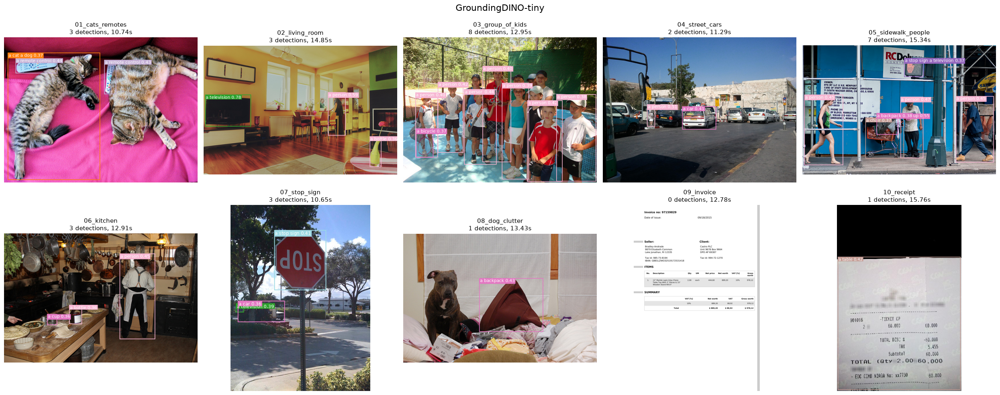

GroundingDINO-tiny: load 3.7s | avg 13.07s/image | 31 detections total


,detections
image,
01_cats_remotes,"a remote control×2, a cat a dog×1"
02_living_room,"a television×1, a bottle×1, a person×1"
03_group_of_kids,"a person×7, a bicycle×1"
04_street_cars,"a person×1, a car×1"
05_sidewalk_people,"a person×3, a cup×1, a chair×1, a stop sign a ..."
06_kitchen,"a person×1, a bottle×1, a cup×1"
07_stop_sign,"a stop sign×1, a television×1, a car×1"
08_dog_clutter,a backpack×1
10_receipt,a table×1


In [9]:
from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor

t = time.time()
proc = AutoProcessor.from_pretrained("IDEA-Research/grounding-dino-tiny")
model = AutoModelForZeroShotObjectDetection.from_pretrained("IDEA-Research/grounding-dino-tiny").to(DEVICE).eval()
load_s = time.time() - t

results, times = {}, {}
for name, img in IMAGES.items():
    text = ". ".join(q.lower() for q in prompts_for(name)) + "."
    t = time.time()
    inputs = proc(images=img, text=text, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = model(**inputs)
    res = proc.post_process_grounded_object_detection(
        out, inputs.input_ids, threshold=GDINO_BOX_THR, text_threshold=GDINO_TEXT_THR,
        target_sizes=[img.size[::-1]])[0]
    labels = res.get("text_labels", res.get("labels"))
    results[name] = [{"label": l if l else "?", "score": float(s), "box": b.tolist()}
                     for s, l, b in zip(res["scores"], labels, res["boxes"])]
    times[name] = time.time() - t

record("GroundingDINO-tiny", results, load_s, times)
free(model, proc)

---
## Summary — speed and detection counts

In [10]:
summary = pd.DataFrame(SUMMARY).set_index("model")
detections = pd.DataFrame(ALL_ROWS)
summary.to_csv(OUT_DIR / "summary.csv"); detections.to_csv(OUT_DIR / "detections.csv", index=False)
display(summary)

counts = detections.pivot_table(index="image", columns="model", values="label", aggfunc="count", fill_value=0)
counts = counts.reindex(index=list(IMAGES), columns=summary.index, fill_value=0)
display(counts)
print(f"saved: {OUT_DIR/'summary.csv'}, {OUT_DIR/'detections.csv'}, annotated images in {OUT_DIR}/<model>/")

,device,load_s,avg_s_per_image,total_detections
model,,,,
YOLOX-S,cpu,0.4,0.41,61
YOLOX-X,cpu,1.8,2.02,71
RT-DETR-R50VD,cpu,2.0,4.73,73
OWLv2-base16-ensemble,cpu,2.5,7.75,38
GroundingDINO-tiny,cpu,3.7,13.07,31


model,YOLOX-S,YOLOX-X,RT-DETR-R50VD,OWLv2-base16-ensemble,GroundingDINO-tiny
image,,,,,
01_cats_remotes,5,5,5,4,3
02_living_room,11,14,15,6,3
03_group_of_kids,16,15,14,2,8
04_street_cars,11,14,14,18,2
05_sidewalk_people,5,6,7,4,7
06_kitchen,9,12,12,0,3
07_stop_sign,1,2,1,2,3
08_dog_clutter,3,3,3,2,1
09_invoice,0,0,1,0,0


saved: /home/tsubame/deeplearning/dimer_model_test/object_detection_test/outputs/summary.csv, /home/tsubame/deeplearning/dimer_model_test/object_detection_test/outputs/detections.csv, annotated images in /home/tsubame/deeplearning/dimer_model_test/object_detection_test/outputs/<model>/


## Side-by-side: every model on one image

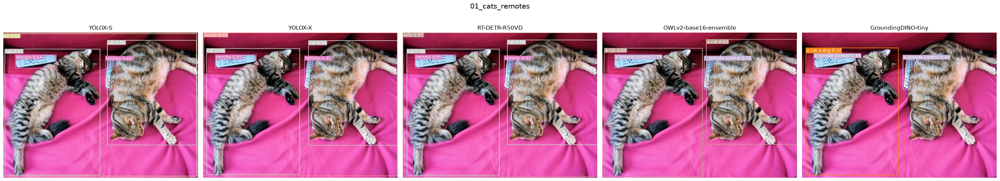

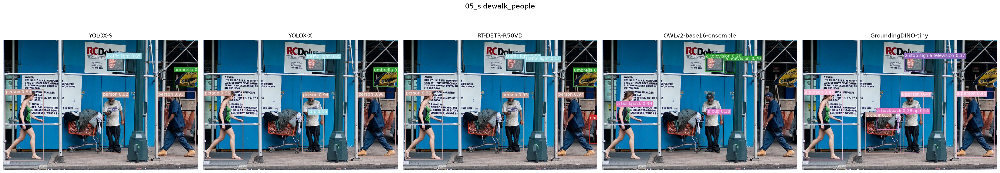

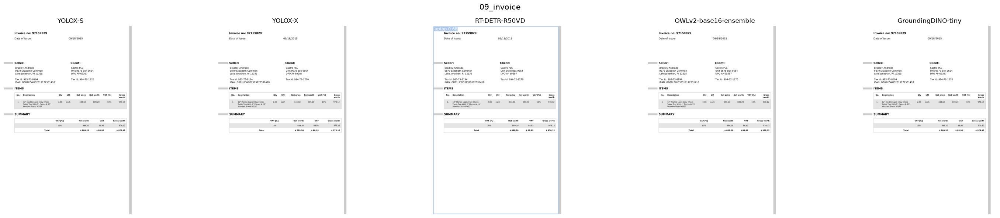

In [11]:
def compare(image_name):
    models = list(summary.index)
    fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 6))
    for ax, m in zip(axes, models):
        ax.imshow(Image.open(OUT_DIR / m / f"{image_name}.jpg")); ax.set_title(m, fontsize=12); ax.axis("off")
    fig.suptitle(image_name, fontsize=15); plt.tight_layout(); plt.show()

compare("01_cats_remotes")
compare("05_sidewalk_people")
compare("09_invoice")

## Full detection list (every box, every model)

In [12]:
pd.set_option("display.max_rows", 500)
detections.sort_values(["image", "model", "score"], ascending=[True, True, False]).reset_index(drop=True)

,model,image,label,score,x1,y1,x2,y2
0,GroundingDINO-tiny,01_cats_remotes,a remote control,0.439,38.6,69.4,176.9,118.0
1,GroundingDINO-tiny,01_cats_remotes,a remote control,0.425,331.6,74.2,370.8,187.3
2,GroundingDINO-tiny,01_cats_remotes,a cat a dog,0.366,13.0,50.7,317.5,471.1
3,OWLv2-base16-ensemble,01_cats_remotes,a remote control,0.794,40.5,73.3,175.3,117.3
4,OWLv2-base16-ensemble,01_cats_remotes,a remote control,0.706,334.8,77.4,368.6,187.3
5,OWLv2-base16-ensemble,01_cats_remotes,a cat,0.690,6.6,51.4,329.1,476.8
6,OWLv2-base16-ensemble,01_cats_remotes,a cat,0.632,341.8,22.8,640.0,370.2
7,RT-DETR-R50VD,01_cats_remotes,sofa,0.970,0.1,0.4,640.1,476.2
8,RT-DETR-R50VD,01_cats_remotes,cat,0.960,343.4,24.3,640.1,371.5
9,RT-DETR-R50VD,01_cats_remotes,cat,0.958,13.2,54.2,319.0,472.2
